In [1]:
import cv2
import time
import numpy as np
import matplotlib.pyplot as plt

from scipy.signal import butter, filtfilt
from sklearn.preprocessing import MinMaxScaler

import pywt
import torch
import torch.nn as nn

from PIL import Image
from torchvision import transforms

In [2]:
device = torch.device("cpu")

print(device)

cpu


In [3]:
from scipy.signal import butter, filtfilt
from sklearn.preprocessing import MinMaxScaler

def preprocess_ppg(ppg, fs):

    b, a = butter(
        4,
        [0.5/(fs/2), 8/(fs/2)],
        btype="band"
    )

    filtered = filtfilt(b, a, ppg)

    scaler = MinMaxScaler()

    normalized = scaler.fit_transform(
        filtered.reshape(-1,1)
    ).flatten()

    return normalized

In [4]:
camera = cv2.VideoCapture(0)

red_signal = []

fps = 30

duration = 30

print("Place finger on webcam...")

start = time.time()

while time.time()-start < duration:

    ret, frame = camera.read()

    if not ret:
        break

    red = frame[:,:,2]

    red_signal.append(
        np.mean(red)
    )

    cv2.imshow(
        "Finger Detection",
        frame
    )

    if cv2.waitKey(1)==27:
        break

camera.release()
cv2.destroyAllWindows()

print("Recording Complete")

Place finger on webcam...
Recording Complete


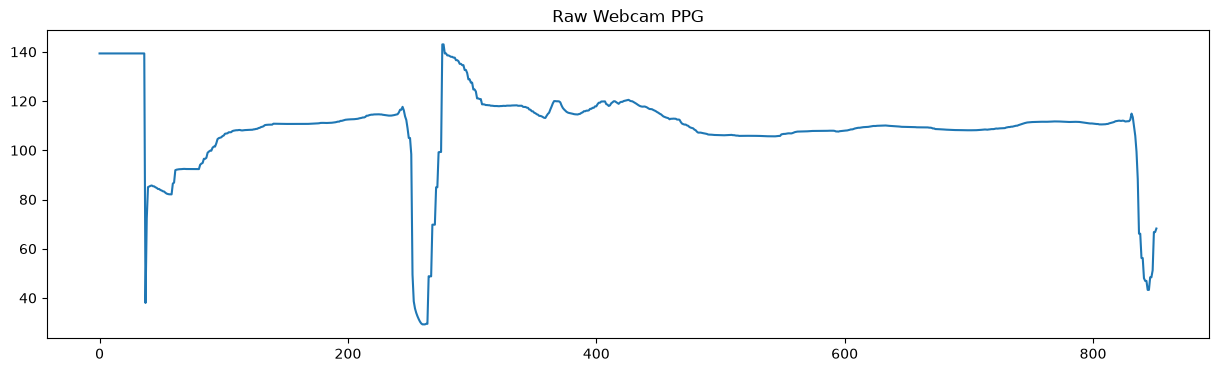

In [5]:
plt.figure(figsize=(15,4))

plt.plot(red_signal)

plt.title("Raw Webcam PPG")

plt.show()

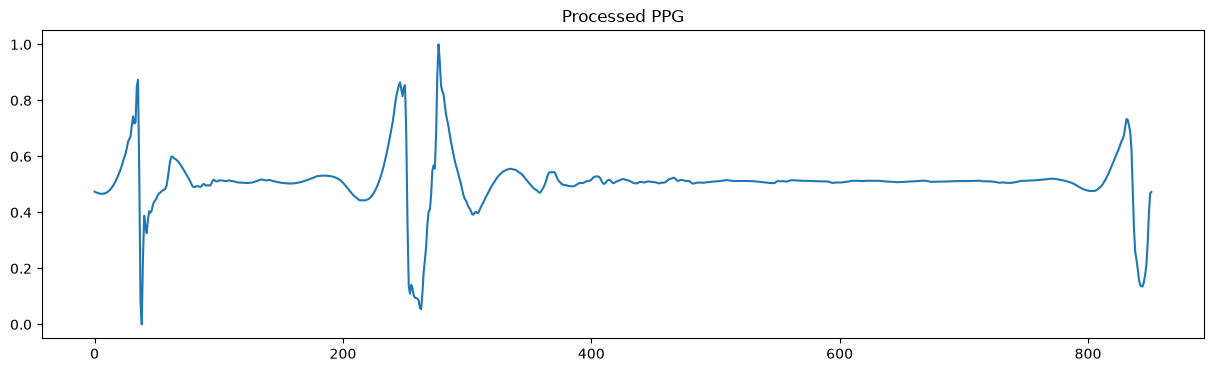

In [6]:
fs = 30

processed = preprocess_ppg(
    np.array(red_signal),
    fs
)

plt.figure(figsize=(15,4))

plt.plot(processed)

plt.title("Processed PPG")

plt.show()

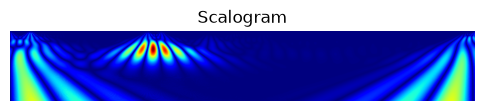

In [7]:
coef, freq = pywt.cwt(
    processed,
    np.arange(1,129),
    "morl"
)

img = np.abs(coef)

img -= img.min()

img /= img.max()

plt.figure(figsize=(6,6))

plt.imshow(img,cmap="jet")

plt.axis("off")

plt.title("Scalogram")

plt.show()

In [8]:
import cv2

img = (img*255).astype(np.uint8)

img = cv2.applyColorMap(
    img,
    cv2.COLORMAP_JET
)

img = cv2.resize(
    img,
    (224,224)
)

cv2.imwrite(
    "live_scalogram.png",
    img
)

print("Saved!")

Saved!


In [9]:
transform = transforms.Compose([

    transforms.ToTensor()

])

In [11]:
import torch
import torch.nn as nn

class BPNet(nn.Module):

    def __init__(self):
        super(BPNet, self).__init__()

        self.features = nn.Sequential(

            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.regressor = nn.Sequential(

            nn.Flatten(),

            nn.Linear(256 * 14 * 14, 512),
            nn.ReLU(),
            nn.Dropout(0.4),

            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(128, 2)
        )

    def forward(self, x):

        x = self.features(x)
        x = self.regressor(x)

        return x

In [12]:
device = torch.device("cpu")

model = BPNet().to(device)

model.load_state_dict(
    torch.load(
        "bp_model_final.pth",
        map_location=device
    )
)

model.eval()

print("✅ Model Loaded Successfully")

✅ Model Loaded Successfully


In [13]:
image = Image.open(
    "live_scalogram.png"
).convert("RGB")

image = transform(image)

image = image.unsqueeze(0)

In [15]:
with torch.no_grad():

    image = image.to(device)

    prediction = model(image)

prediction = prediction.cpu().numpy()[0]

sbp = prediction[0]
dbp = prediction[1]

print("="*50)
print("Predicted Blood Pressure")
print("="*50)
print(f"SBP : {sbp:.2f} mmHg")
print(f"DBP : {dbp:.2f} mmHg")

Predicted Blood Pressure
SBP : 122.45 mmHg
DBP : 57.87 mmHg


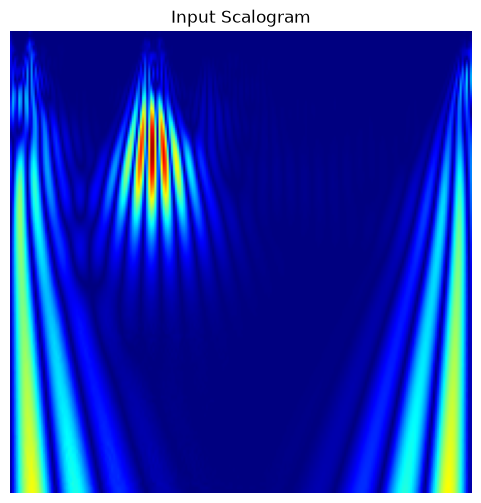

In [16]:
plt.figure(figsize=(6,6))
plt.imshow(Image.open("live_scalogram.png"))
plt.axis("off")
plt.title("Input Scalogram")
plt.show()

In [17]:
print("="*60)
print("AI Blood Pressure Estimation")
print("="*60)

print(f"Systolic BP  : {sbp:.1f} mmHg")
print(f"Diastolic BP : {dbp:.1f} mmHg")

print("="*60)

AI Blood Pressure Estimation
Systolic BP  : 122.5 mmHg
Diastolic BP : 57.9 mmHg


In [19]:
import os
import pandas as pd
from datetime import datetime

result = pd.DataFrame({
    "Date": [datetime.now()],
    "SBP": [sbp],
    "DBP": [dbp]
})

result.to_csv(
    "prediction_history.csv",
    mode="a",
    header=not os.path.exists("prediction_history.csv"),
    index=False
)

print("Prediction saved!")

Prediction saved!


In [20]:
import pandas as pd
from datetime import datetime

result = pd.DataFrame({
    "Date":[datetime.now()],
    "SBP":[sbp],
    "DBP":[dbp]
})

result.to_csv(
    "prediction_history.csv",
    mode="a",
    header=not os.path.exists("prediction_history.csv"),
    index=False
)

print("Prediction saved!")

Prediction saved!


In [21]:
history = pd.read_csv("prediction_history.csv")

history.tail()

,Date,SBP,DBP
0,2026-08-07 19:04:07.229047,122.451706,57.86501
1,2026-08-07 19:04:09.530595,122.451706,57.86501
